# Stray pixels and images in pieces

### What you will learn

1. what a drop with stray pixels, and an image in pieces, look like;
2. why a few stray pixels can change a particle's size several-fold, using the package's own sizing;
3. what the package's stray-pixel correction does, and what it does *not* do for an image in pieces;
4. what is known about how often this happens;
5. how to count the affected images in your own data;
6. what is on by default.

### What data this uses

None from disk. Every image is **synthetic**, drawn on a 48 x 48 pixel canvas.

**Before this:** [05_triage_and_gallery](../1_getting_started/05_triage_and_gallery.ipynb) (Looking at particles: a contact sheet, a gallery, and the triage page), [12_particle_gallery](12_particle_gallery.ipynb) (What is not a particle: a gallery of optical array probe artifacts). **Related:** [04_stray_pixel_images](04_stray_pixel_images.ipynb). **Needs:** `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

The next cell checks that the notebook runs from the repository root, where the paths below start.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/5_data_quality/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

import sys

if "examples" not in sys.path:  # shared helper modules (_style.py) sit in examples/
    sys.path.insert(0, "examples")

## 1. What each artifact looks like

An image is a boolean array: `True` where a diode was in shadow. Panels draw time (slices) along the horizontal axis and the
diodes along the vertical axis (the arrow key on the first panel); diode 1 is at the top. Left: a **drop plus stray pixels**, a real round drop with two isolated shadowed pixels far
from it. Right: an **image in pieces**, one round particle whose middle is lit, so the shadow
splits into two disconnected parts. The bar below each panel is 100 µm, assuming 10 µm per pixel
(pixel size differs between probes, so rescale for yours).

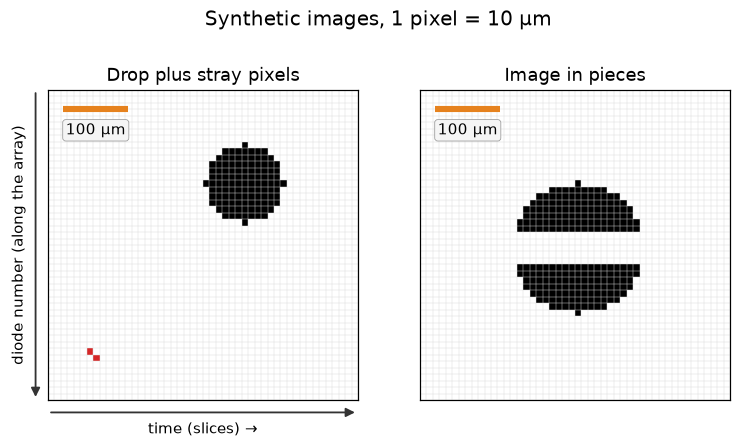

In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

N = 48
ii, jj = np.mgrid[0:N, 0:N]

def disc(ci, cj, d):
    return (ii - ci) ** 2 + (jj - cj) ** 2 <= (d / 2) ** 2

drop = disc(30, 14, 12)
stray = drop.copy()
stray[6, 40] = stray[7, 41] = True                       # two far-off pixels
pieces = disc(24, 24, 20) & ~((jj >= 22) & (jj <= 26))   # a lit gap through the particle

PX_UM = 10.0   # assumed pixel size (um); the scale bar uses it

import _style                  # house style: _style.py sits beside this notebook
_style.apply()

def show(ax, img, title, red=None, circle_um=None):
    key = not getattr(ax.figure, "_keyed", False)       # direction key on the first panel of each figure
    ax.figure._keyed = True
    _style.pixels(ax, img, red=red, circle_um=circle_um, um_per_px=PX_UM, title=title, time_x=True, key=key, bar_top=True)   # bar at the top: the stray pixels sit bottom-left

fig, axs = plt.subplots(1, 2, figsize=(8, 4.4))
show(axs[0], stray, "Drop plus stray pixels", red=stray & ~drop)
show(axs[1], pieces, "Image in pieces")
fig.suptitle("Synthetic images, 1 pixel = 10 µm")
fig.savefig("examples/figures/stray_artifacts.png", dpi=110, bbox_inches="tight")
plt.show()

## 2. Why it matters: the size changes

The engine sizes a particle with the smallest circle that encloses every shadowed pixel. The
function is `arrayprobe_uiops.min_circle.cgal_min_r_v35`, which `measure_record`
(`src/arrayprobe_uiops/measure.py:224`, `:264`) calls for every particle. If the enclosing circle
has diameter $D$, the particle is treated as a sphere of that diameter, so one shadowed pixel
with $L$ empty pixels between it and the drop's near edge makes $D \approx d_{\rm drop} + L$
rather than $d_{\rm drop}$ (`min_circle.py:203`, $D = 1 + 2\sqrt{r^2}$ pixels). Water
content grows as $D^3$, so the error compounds:

$$ \frac{M_{\rm with}}{M_{\rm without}} \approx \left(\frac{D_{\rm with}}{D_{\rm without}}\right)^{3}. $$

The function returns a diameter in pixels, not a radius: its docstring names the first output
`diameter` and the line is `diameter = 1.0 + 2.0 * math.sqrt(r2)` (`min_circle.py:171`, `:203`), so a
12-pixel disc returns 13. Below, the same drop is sized without and with the stray pixels,
and the engine's reject test (`calculate_reject_unified`, `arrayprobe_uiops/reject.py`) is run on both.

In [3]:
from arrayprobe_uiops.min_circle import cgal_min_r_v35
from arrayprobe_uiops.reject import calculate_reject_unified, is_it_hollow
from arrayprobe_uiops.reject_core import RejectConfig

def size_px(img):
    codes = np.where(img, 48, 49).astype(np.int64)     # 48 = shadowed, as the engine reads it
    return cgal_min_r_v35(codes, 1.0)[0]               # tas_ratio 1: no stretching

def reject(img):
    codes = np.where(img, 48, 49).astype(np.int64)
    hollow = int(is_it_hollow(img, N)[0])
    return calculate_reject_unified(codes, "S", hollow, RejectConfig()).reject_status

d0, d1 = size_px(drop), size_px(stray)
print(f"drop alone:          size {d0:5.1f} px = {d0 * PX_UM:5.0f} um, reject code {reject(drop)!r}")
print(f"drop plus 2 strays:  size {d1:5.1f} px = {d1 * PX_UM:5.0f} um, reject code {reject(stray)!r}")
print(f"diameter x{d1 / d0:.2f}, volume (and water content) x{(d1 / d0) ** 3:.1f}")

drop alone:          size  13.0 px =   130 um, reject code '0'
drop plus 2 strays:  size  42.2 px =   422 um, reject code 's'
diameter x3.25, volume (and water content) x34.3


The reject code `'0'` means the engine accepts the particle, and any other letter rejects it
(`arrayprobe_uiops/reject.py:373-432`). In this example the ordinary tests reject the strayed image, because
its enclosing circle is mostly empty. That is not guaranteed: a stray pixel next to a larger
particle fills more of the circle and can pass. How the size grows with the distance of one stray pixel:

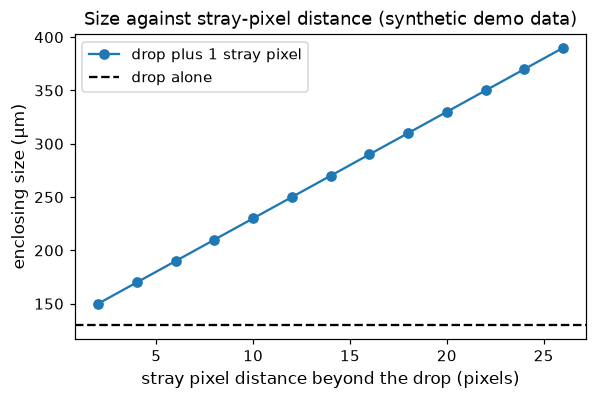

In [4]:
dist = np.arange(2, 27, 2)                     # stray distance from the drop edge (pixels)
sizes = []
for L in dist:
    im = drop.copy()
    im[30, 20 + L] = True                      # one pixel, L empty pixels beyond the drop edge
    sizes.append(size_px(im))
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(dist, np.array(sizes) * PX_UM, "o-", label="drop plus 1 stray pixel")
ax.axhline(d0 * PX_UM, color="k", ls="--", label="drop alone")
ax.set_xlabel("stray pixel distance beyond the drop (pixels)")
ax.set_ylabel("enclosing size (µm)")
ax.set_title("Size against stray-pixel distance (synthetic demo data)")
ax.legend(fontsize=10)
plt.show()

*Figure 2. Enclosing size of a synthetic drop plus one stray pixel, against the stray pixel's distance beyond the drop edge; the dashed line is the size of the drop alone.*

## 3. What the package does

### Drop plus stray pixels: `remove_stray_pixels`

`remove_stray_pixels` (`src/arrayprobe_uiops/stray_pixel.py:44`) groups the shadowed pixels into
pieces that lie within `gap` empty diodes of one another (default 8, `STRAY_GAP_DIODES`). It
corrects only when exactly one group is a main piece (more than `n_stray` = 2 pixels and at least
`min_main` = 9) and every other group has at most 2 pixels. Those strays are zeroed and the image
goes back through the unchanged sizing and reject code. Otherwise the image is returned untouched.

removed 2 pixels in 1 stray group(s) at (slice, diode) [(6, 40), (7, 41)]
size before  42.2 px, after  13.0 px (drop alone  13.0 px); reject code before 's', after '0'


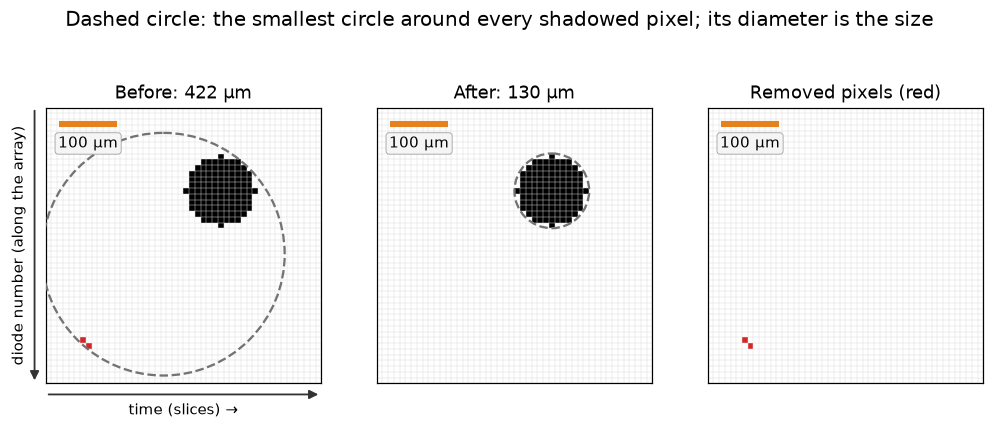

In [5]:
from arrayprobe_uiops.stray_pixel import remove_stray_pixels

cleaned, rec = remove_stray_pixels(stray.astype(np.uint8))
clean = cleaned.astype(bool)
print(f"removed {rec['removed']} pixels in {rec['pieces']} stray group(s) at (slice, diode) {rec['positions']}")
print(f"size before {size_px(stray):5.1f} px, after {size_px(clean):5.1f} px "
      f"(drop alone {size_px(drop):5.1f} px); reject code before {reject(stray)!r}, after {reject(clean)!r}")

fig, axs = plt.subplots(1, 3, figsize=(11, 4.4))
show(axs[0], stray, f"Before: {size_px(stray) * PX_UM:.0f} µm", red=stray ^ clean,
     circle_um=size_px(stray) * PX_UM)
show(axs[1], clean, f"After: {size_px(clean) * PX_UM:.0f} µm", circle_um=size_px(clean) * PX_UM)
show(axs[2], stray ^ clean, "Removed pixels (red)", red=stray ^ clean)
fig.suptitle("Dashed circle: the smallest circle around every shadowed pixel; its diameter is the size")
fig.savefig("examples/figures/stray_before_after.png", dpi=110, bbox_inches="tight")
plt.show()

The correction has limits, each set by a parameter of the function. The cell below probes them
on the same drop.

In [6]:
def attempt(extra, **kw):
    im = drop.copy()
    for r, c in extra:
        im[r, c] = True
    _, rec = remove_stray_pixels(im.astype(np.uint8), **kw)
    return rec["removed"]

print("2 strays, far away:            removed", attempt([(6, 40), (7, 41)]))
print("3 pixels in a row, far away:   removed", attempt([(6, 40), (6, 41), (6, 42)]))
print("1 stray 4 empty diodes away:   removed", attempt([(30, 25)]))
print("two far groups of 1 pixel:     removed", attempt([(6, 40), (44, 44)]))
print("1 stray 4 away, but gap=3:     removed", attempt([(30, 25)], gap=3))

2 strays, far away:            removed 2
3 pixels in a row, far away:   removed 0
1 stray 4 empty diodes away:   removed 0
two far groups of 1 pixel:     removed 2
1 stray 4 away, but gap=3:     removed 1


A group of three pixels counts as part of the particle (`n_stray` = 2), and a pixel within
8 empty diodes of the drop joins it, since a gap that small also occurs inside real particles. Both
are choices of the default; they move with the arguments.

### Image in pieces: what the engine does

The engine does not regroup the pieces. The stray-pixel correction leaves this image alone:
the two pieces lie within 8 diodes of each other, so they are one group, and the correction needs two or more groups (and a stray of at most 2 pixels). Grouping of
pieces with a gap exists in the review tool (`arrayprobe.triage_context.piece_groups`,
`triage_context.py:89`, gap of 8 diodes as in `stray_pixel.py:12`), not in processing.

In [7]:
from arrayprobe.triage_context import piece_groups

_, rec_p = remove_stray_pixels(pieces.astype(np.uint8))
print(f"remove_stray_pixels removes {rec_p['removed']} pixels (one group at gap 8, nothing to remove)")
print(f"pieces at gap 0 (plain 8-connectivity): {[int(g.sum()) for g in piece_groups(pieces, gap=0)]} px")
print(f"pieces at gap 8 (review tool default):  {[int(g.sum()) for g in piece_groups(pieces, gap=8)]} px")
print(f"engine: size {size_px(pieces):.1f} px = {size_px(pieces) * PX_UM:.0f} um, reject code {reject(pieces)!r}")

remove_stray_pixels removes 0 pixels (one group at gap 8, nothing to remove)
pieces at gap 0 (plain 8-connectivity): [110, 110] px
pieces at gap 8 (review tool default):  [220] px
engine: size 21.0 px = 210 um, reject code '0'


The engine sees one object whose enclosing circle spans both pieces, so the size is right here:
the pieces belong to one round particle. The reject test then decides (`arrayprobe_uiops/reject.py:373-432`).
The engine has no step that groups, rejects or merges pieces as such; the grouping lives in the
review tool.

### The measured quantities as a labelled dataset

Sizes, reject codes and removed pixels of the three images, in an `xarray.Dataset` whose variables
carry `units` attributes.

In [8]:
import pandas as pd
import xarray as xr

imgs = {"drop": drop, "drop + strays": stray, "image in pieces": pieces}

def var(name, values, units):
    return xr.DataArray(values, dims="image", coords={"image": list(imgs)},
                        attrs={"units": units}, name=name)

ds = xr.merge([
    var("size", [size_px(im) * PX_UM for im in imgs.values()], "um"),
    var("size_pixels", [size_px(im) for im in imgs.values()], "pixel"),
    var("stray_removed", [remove_stray_pixels(im.astype(np.uint8))[1]["removed"]
                          for im in imgs.values()], "pixel"),
])
ds.attrs["title"] = "Synthetic stray-pixel examples, package results"
ds

<xarray.Dataset> Size: 252B
Dimensions:        (image: 3)
Coordinates:
  * image          (image) <U15 180B 'drop' 'drop + strays' 'image in pieces'
Data variables:
    size           (image) float64 24B 130.0 422.3 210.0
    size_pixels    (image) float64 24B 13.0 42.23 21.0
    stray_removed  (image) int64 24B 0 2 0
Attributes:
    units:    um
    title:    Synthetic stray-pixel examples, package results

The same numbers as a table, with the units in the column names and the reject code added.

In [9]:
df = ds.to_dataframe()
df.columns = [f"{c} ({ds[c].attrs['units']})" for c in df.columns]
df["reject code"] = [reject(im) for im in imgs.values()]
df

,size (um),size_pixels (pixel),stray_removed (pixel),reject code
image,,,,
drop,130.000000,13.000000,0,0
drop + strays,422.310563,42.231056,2,s
image in pieces,210.000000,21.000000,0,0


The drop with strays is sized several times larger than the drop alone, and the correction
(section 3) brings it back; the image in pieces keeps one size because the engine sees one object.

## 4. How often

- **Drop plus stray pixels**: on one field campaign's flight, the correction changed 333 of 15,189
  seconds. Over that whole flight particle number changed by +0.0004 %, water content by +0.003 %
  and the sixth moment by -0.14 dB; the largest single second moved 7.57 dB
  (measured on one field-campaign flight). That is one flight: the per-particle rate is **not measured yet**.
- **Image in pieces**: **not measured yet**.

## 5. Check your own data

Count how many of your images the correction would change. `images` is any list of 2-D arrays,
nonzero where shadowed; the next cell uses the synthetic images of this notebook as a stand-in for yours.

In [10]:
images = [drop, stray, pieces]          # replace with your own list
changed = [remove_stray_pixels(im.astype(np.uint8))[1]["removed"] for im in images]
print(sum(n > 0 for n in changed), "of", len(images), "images would change")

1 of 3 images would change


## 6. Defaults

| | Library | Engine-3.5 batch driver |
|---|---|---|
| Stray-pixel correction | off: `stray_pixel_fix=False` (`arrayprobe_uiops/imgproc.py:571`, `stray_pixel.py:9`) | on for every probe, the archived-product 2D-S and HVPS included (`run_flight.py:1054-1061`, `:1126-1147`) |
| Turn it off | leave the argument | `--stray-pixel off`, or `stray_pixel_fix = false` in the config |
| v3.1.4 port validation | not applicable | not part of this package |
| Grouping of pieces | none in processing | none in processing (review tool only) |

Each run's stamp records the setting (`stray_pixel=`), because the output file alone cannot say.

## What to try next

- Change the last probe in section 3 to put a stray pixel closer than 8 diodes to the drop and watch it stop being removed.
- Add a third pixel to the stray group (`n_stray` = 2) and see the correction decline.
- Shrink the drop to 2 or 3 pixels across: `min_main` = 9 stops the correction, since the
  main piece is then too small to be told from a stray.
- Next: [15_hollow_rings.ipynb](15_hollow_rings.ipynb), drops far from focus that image as rings.